# Cramér's V between Specific Predictor Variables (Children < 2)

This notebook computes the bias-corrected Cramér's V between a specific set of predictor variables for children aged under 2.

## Variables analyzed:
`bd9`, `fg_grain`, `fg_legume`, `fg_dairy`, `fg_flesh`, `fg_egg`, `fg_vita`, `fg_ofv`, `dds`, `fvs`, `anc_cat`, `bf_status`, `bottle`, `small_at_birth`, `low_bw`, `suppl_yday`, `birth_size`

In [1]:
import warnings, os
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats

DATA_FILE = 'MICS-child-ISRC-revised.dta'
SEARCH_DIRS = ['.', '..', 'data']

def find_file(name):
    for d_ in SEARCH_DIRS:
        p_ = os.path.join(d_, name)
        if os.path.exists(p_): return p_
    return None

path = find_file(DATA_FILE)
if path is None: raise FileNotFoundError(f'{DATA_FILE} not found.')
data = pd.read_stata(path, convert_categoricals=False)

# Filter for children under 2
u2 = data[data['ub2'] < 2].reset_index(drop=True)
print(f'Children aged < 2: {len(u2):,}')

Children aged < 2: 8,888


In [2]:
def contingency(a, b):
    m = (a >= 0) & (b >= 0)
    a2, b2 = a[m], b[m]
    if len(a2) == 0: return np.zeros((0, 0))
    ua, ub = np.unique(a2), np.unique(b2)
    ia, ib = np.searchsorted(ua, a2), np.searchsorted(ub, b2)
    return np.bincount(ia * len(ub) + ib, minlength=len(ua) * len(ub)).reshape(len(ua), len(ub))

def v_stats(t):
    r, c = t.shape; n = t.sum()
    if r < 2 or c < 2 or n <= 1: return {'V_corr': np.nan, 'p': np.nan, 'n': n, 'V': np.nan, 'chi2': np.nan}
    E = t.sum(1, keepdims=True) @ t.sum(0, keepdims=True) / n
    chi2 = float(((t - E) ** 2 / E).sum())
    phi2 = chi2 / n
    phi2c = max(0.0, phi2 - (r - 1) * (c - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    cc = c - (c - 1) ** 2 / (n - 1)
    return {
        'V_corr': float(np.sqrt(phi2c / max(min(rc - 1, cc - 1), 1e-12))),
        'p': float(stats.chi2.sf(chi2, (r - 1) * (c - 1))),
        'n': float(n),
        'V': float(np.sqrt(phi2 / max(min(r - 1, c - 1), 1e-12))),
        'chi2': chi2
    }

def size_label(v, k):
    if not np.isfinite(v): return ''
    th = {1: (0.10, 0.30, 0.50), 2: (0.07, 0.21, 0.35), 3: (0.06, 0.17, 0.29)}.get(k, (0.05, 0.15, 0.25))
    return 'large' if v >= th[2] else 'medium' if v >= th[1] else 'small' if v >= th[0] else 'negligible'

def recode_simple(s):
    c = pd.Categorical(s)
    return c.codes.astype(int)

In [3]:
target_vars = [
    'bd9', 'fg_grain', 'fg_legume', 'fg_dairy', 'fg_flesh', 'fg_egg', 'fg_vita', 'fg_ofv',
    'dds', 'fvs', 'anc_cat', 'bf_status', 'bottle', 'small_at_birth', 'low_bw', 'suppl_yday', 'birth_size'
]

CODES = {v: recode_simple(u2[v]) for v in target_vars if v in u2.columns}
missing = set(target_vars) - set(CODES.keys())
if missing: print(f'Missing variables: {missing}')

valid_vars = list(CODES.keys())
results = []
for i, a in enumerate(valid_vars):
    for b in valid_vars[i+1:]:
        t = contingency(CODES[a], CODES[b])
        st = v_stats(t)
        k = min(t.shape[0]-1, t.shape[1]-1) if t.size > 0 else 0
        results.append({
            'var1': a, 'var2': b, 'n': st['n'], 'V_corr': st['V_corr'], 
            'V': st['V'], 'p': st['p'], 'size': size_label(st['V_corr'], k)
        })

vv_df = pd.DataFrame(results).sort_values('V_corr', ascending=False)
print("\nVariable-Variable Cramér's V (Bias-Corrected):")
print(vv_df[['var1', 'var2', 'n', 'V_corr', 'V', 'size', 'p']].round(3).to_string(index=False))

# Matrix
matrix = pd.DataFrame(np.eye(len(valid_vars)), index=valid_vars, columns=valid_vars)
for r in results:
    v1 = r['var1']
    v2 = r['var2']
    val = r['V_corr']
    matrix.loc[v1, v2] = val
    matrix.loc[v2, v1] = val
print("\nCorrelation Matrix:")
print(matrix.round(3))


Variable-Variable Cramér's V (Bias-Corrected):
          var1           var2      n  V_corr     V       size     p
small_at_birth     birth_size 8588.0   1.000 1.000      large 0.000
      fg_grain            fvs 8799.0   0.865 0.866      large 0.000
      fg_grain            dds 8815.0   0.850 0.850      large 0.000
           dds            fvs 8799.0   0.713 0.714      large 0.000
      fg_flesh            dds 8815.0   0.653 0.653      large 0.000
      fg_flesh            fvs 8799.0   0.645 0.646      large 0.000
       fg_vita            fvs 8799.0   0.630 0.632      large 0.000
       fg_vita            dds 8815.0   0.622 0.623      large 0.000
        fg_ofv            dds 8815.0   0.617 0.618      large 0.000
        fg_egg            dds 8815.0   0.614 0.615      large 0.000
        fg_ofv            fvs 8799.0   0.579 0.580      large 0.000
        fg_egg            fvs 8799.0   0.571 0.573      large 0.000
        low_bw     birth_size 6162.0   0.525 0.526      large 0.000


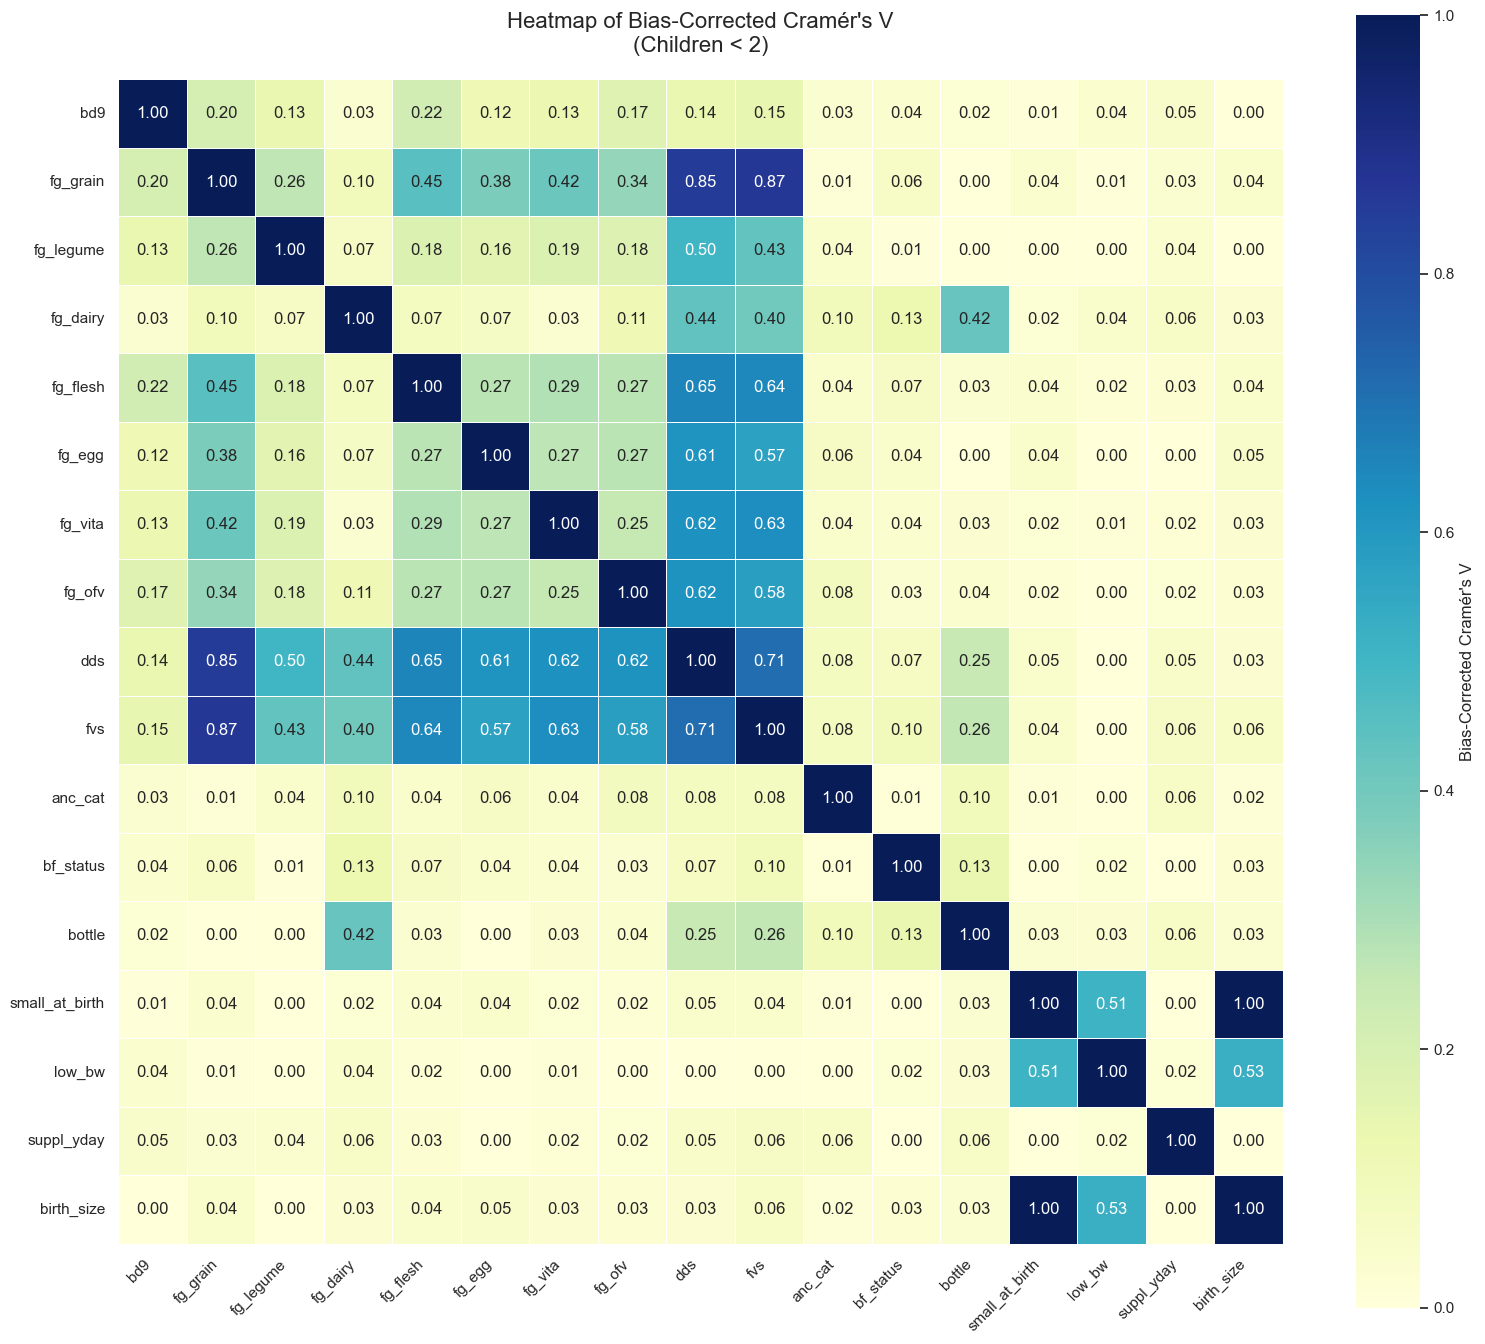

In [4]:
# Heatmap Implementation
plt.figure(figsize=(16, 14))
sns.set_theme(style="white")

heatmap = sns.heatmap(
    matrix, 
    annot=True, 
    fmt=".2f", 
    cmap="YlGnBu", 
    linewidths=.5, 
    cbar_kws={'label': "Bias-Corrected Cramér's V"},
    square=True
)

plt.title("Heatmap of Bias-Corrected Cramér's V\n(Children < 2)", fontsize=16, pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()